# KKBox Music Subscription Churn

**Question:** which subscribers whose plan expires in February 2017 will not renew, why, and what should we do about it?

**Data** (KKBox, WSDM 2018 Kaggle challenge): `train.csv` labels, `members_v3.csv` profiles, `transactions.csv` payments, `user_logs.csv` daily listening (30 GB).
Features are built by `src/build_features.py`, which streams the raw files through DuckDB SQL and writes one row per subscriber to `data/features.parquet`.

**Churn definition (from KKBox):** no new valid subscription within 30 days after the current membership expires.

**Leakage guard:** every feature uses data on or before **31 Jan 2017**. The raw transactions file runs to 28 Feb, so it contains some renewals that happen inside the churn window; using them would inflate the model's score.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
import xgboost as xgb

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

df = pd.read_parquet("../data/features.parquet")
# DuckDB writes nullable integer columns; plain floats (NaN for missing) are simpler to work with.
num_cols = df.columns.drop(["msno", "gender"])
df[num_cols] = df[num_cols].astype("float64")
base_rate = df.is_churn.mean()
print(f"subscribers: {len(df):,}   churned: {df.is_churn.sum():,}   baseline churn: {base_rate:.2%}")

subscribers: 992,931   churned: 63,471.0   baseline churn: 6.39%


## 1. Data overview

Coverage of each source for the labelled cohort. Users missing a profile or listening logs are kept, with `has_profile` / `has_logs` flags, rather than dropped.

In [2]:
coverage = pd.Series({
    "has member profile": df.has_profile.mean(),
    "has transactions": df.n_transactions.notna().mean(),
    "has listening logs": df.has_logs.mean(),
    "age recorded (10-80)": df.age.notna().mean(),
})
coverage.to_frame("share of subscribers")

,share of subscribers
has member profile,0.883
has transactions,0.998
has listening logs,0.872
age recorded (10-80),0.392


## 2. Exploratory analysis: what separates churners?

In [3]:
df["plan_length"] = np.select(
    [df.plan_days < 30, df.plan_days == 30, df.plan_days > 30],
    ["< 30 days", "30 days", "> 30 days"], default="unknown")
df["cancel_history"] = pd.cut(df.n_cancels, [-1, 0, 1, 1000], labels=["never", "once", "2+ times"])
df["activity_30d"] = pd.cut(df.active_days_30, [-1, 0, 5, 15, 30],
                            labels=["0 days", "1-5 days", "6-15 days", "16-30 days"])

def churn_by(col):
    return (df.groupby(col, observed=True).is_churn
              .agg(users="size", churn_rate="mean"))

drivers = {
    "auto_renew": "Auto-renew on last transaction",
    "last_tx_cancel": "Last transaction was a cancellation",
    "plan_length": "Plan length",
    "activity_30d": "Active listening days, last 30",
    "cancel_history": "Past cancellations",
}
for col, title in drivers.items():
    print(f"\n{title}")
    print(churn_by(col).to_string())


Auto-renew on last transaction
             users  churn_rate
auto_renew                    
0.000       112108       0.324
1.000       878726       0.030

Last transaction was a cancellation


                 users  churn_rate
last_tx_cancel                    
0.000           981292       0.056
1.000             9542       0.795

Plan length
              users  churn_rate
plan_length                    
30 days      964447       0.051
< 30 days      3628       0.733
> 30 days     22759       0.476
unknown        2097       0.316

Active listening days, last 30
               users  churn_rate
activity_30d                    
0 days        218068       0.063
1-5 days      118367       0.078
6-15 days     212187       0.073
16-30 days    444309       0.056

Past cancellations
                 users  churn_rate
cancel_history                    
never           790731       0.060
once            162893       0.070
2+ times         37210       0.112


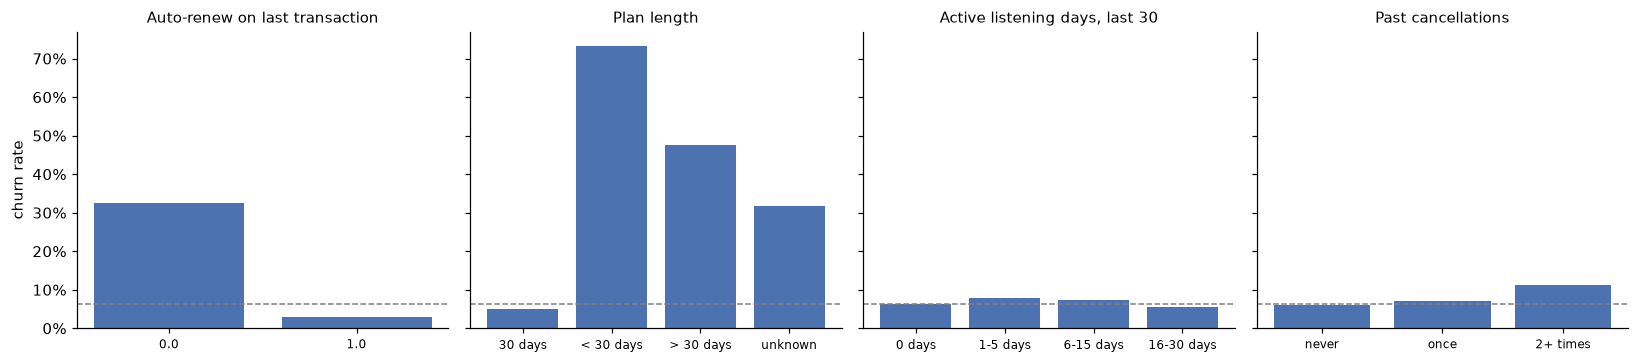

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, col in zip(axes, ["auto_renew", "plan_length", "activity_30d", "cancel_history"]):
    t = churn_by(col)
    ax.bar(t.index.astype(str), t.churn_rate, color="#4C72B0")
    ax.axhline(base_rate, color="grey", ls="--", lw=1)
    ax.set_title(drivers[col], fontsize=10)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("churn rate")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout()

## 3. Hypothesis tests

- **Chi-square** for categorical drivers (is churn independent of the category?), with **Cramér's V** as effect size.
- **Welch's t-test** for numeric drivers (do churners and retained users have different means?), with **Cohen's d** as effect size.

With ~1M users almost any difference is "significant" at p < 0.05, so the effect sizes are what tell us which drivers matter.

In [5]:
def chi2_test(col):
    ct = pd.crosstab(df[col], df.is_churn)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return {"feature": col, "test": "chi-square", "statistic": chi2, "p_value": p,
            "effect_size": v, "effect_measure": "Cramér's V"}

def welch_t(col):
    churned = df.loc[df.is_churn == 1, col].dropna()
    stayed = df.loc[df.is_churn == 0, col].dropna()
    t, p = stats.ttest_ind(churned, stayed, equal_var=False)
    d = (churned.mean() - stayed.mean()) / np.sqrt((churned.var() + stayed.var()) / 2)
    return {"feature": col, "test": "Welch t-test", "statistic": t, "p_value": p,
            "effect_size": d, "effect_measure": "Cohen's d",
            "mean_churned": churned.mean(), "mean_retained": stayed.mean()}

tests = pd.DataFrame(
    [chi2_test(c) for c in ["auto_renew", "last_tx_cancel", "plan_length", "cancel_history"]]
    + [welch_t(c) for c in ["active_days_30", "hours_30", "hours_change",
                            "days_since_last_listen", "subscriber_tenure_days"]]
)
tests["significant (p<0.05)"] = tests.p_value < 0.05
tests

,feature,test,statistic,p_value,effect_size,effect_measure,mean_churned,mean_retained,significant (p<0.05)
0,auto_renew,chi-square,"144,673.699",0.000,0.382,Cramér's V,NaN,NaN,True
1,last_tx_cancel,chi-square,"86,926.832",0.000,0.296,Cramér's V,NaN,NaN,True
2,plan_length,chi-square,"96,541.457",0.000,0.312,Cramér's V,NaN,NaN,True
3,cancel_history,chi-square,"1,767.712",0.000,0.042,Cramér's V,NaN,NaN,True
4,active_days_30,Welch t-test,-27.816,0.000,-0.112,Cohen's d,12.193,13.368,True
5,hours_30,Welch t-test,-17.390,0.000,-0.069,Cohen's d,26.466,29.389,True
6,hours_change,Welch t-test,8.460,0.000,0.036,Cohen's d,1.399,0.533,True
7,days_since_last_listen,Welch t-test,17.791,0.000,0.082,Cohen's d,30.358,23.008,True
8,subscriber_tenure_days,Welch t-test,-59.681,0.000,-0.252,Cohen's d,425.768,488.726,True


## 4. Models

Stratified 80/20 train/test split. Two models:

- **Logistic regression**: interpretable baseline. Numeric features get a signed log transform (to tame heavy tails), median imputation with missing-value flags, and standardisation; categoricals are one-hot encoded.
- **XGBoost**: gradient-boosted trees, which handle missing values and non-linear effects natively. Tree depth is chosen on a validation slice of the training set, with early stopping.

Metrics: **ROC-AUC** (ranking quality) and **PR-AUC** (more informative when only ~6% are positive).

In [6]:
NUM = ["age", "account_age_days", "n_transactions", "n_cancels", "subscriber_tenure_days",
       "share_auto_renew", "plan_days", "auto_renew", "last_tx_cancel", "list_price",
       "amount_paid", "discount", "days_to_expiry", "days_since_last_listen",
       "active_days_30", "active_days_prev30", "hours_30", "hours_prev30", "hours_change",
       "avg_unique_songs_30", "completion_rate_30", "has_logs", "has_profile"]
CAT = ["city", "registered_via", "payment_method", "gender"]

X = df[NUM + CAT].copy()
for c in CAT:
    X[c] = X[c].astype("string").fillna("missing").astype("category")
y = df.is_churn

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train: {len(X_train):,}   test: {len(X_test):,}   test churn rate: {y_test.mean():.2%}")

train: 794,344   test: 198,587   test churn rate: 6.39%


In [7]:
signed_log = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)), feature_names_out="one-to-one")
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), signed_log, StandardScaler()), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100), CAT),
])
logreg = make_pipeline(pre, LogisticRegression(max_iter=2000))
logreg.fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]
print(f"Logistic regression   ROC-AUC {roc_auc_score(y_test, p_lr):.3f}   PR-AUC {average_precision_score(y_test, p_lr):.3f}")

Logistic regression   ROC-AUC 0.865   PR-AUC 0.523


In [8]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.1, stratify=y_train, random_state=SEED)

def fit_xgb(max_depth):
    m = xgb.XGBClassifier(
        n_estimators=3000, learning_rate=0.05, max_depth=max_depth,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
        tree_method="hist", enable_categorical=True, eval_metric="auc",
        early_stopping_rounds=100, random_state=SEED, n_jobs=8)
    m.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    return m

tuning = {}
for depth in [4, 6, 8]:
    m = fit_xgb(depth)
    tuning[depth] = (m, m.best_score, m.best_iteration)
    print(f"max_depth={depth}: validation AUC {m.best_score:.4f} at {m.best_iteration} trees")

best_depth = max(tuning, key=lambda d: tuning[d][1])
model = tuning[best_depth][0]
p_xgb = model.predict_proba(X_test)[:, 1]
print(f"\nXGBoost (max_depth={best_depth})   ROC-AUC {roc_auc_score(y_test, p_xgb):.3f}   PR-AUC {average_precision_score(y_test, p_xgb):.3f}")

max_depth=4: validation AUC 0.8977 at 1025 trees


max_depth=6: validation AUC 0.8973 at 345 trees


max_depth=8: validation AUC 0.8983 at 307 trees



XGBoost (max_depth=8)   ROC-AUC 0.899   PR-AUC 0.578


In [9]:
def top_k_stats(p, k):
    cut = np.quantile(p, 1 - k)
    top = p >= cut
    return y_test[top].mean(), y_test[top].sum() / y_test.sum()

rows = []
for name, p in [("Logistic regression", p_lr), ("XGBoost", p_xgb)]:
    r = {"model": name, "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)}
    for k in [0.05, 0.10, 0.20]:
        rate, recall = top_k_stats(p, k)
        r[f"churners caught in top {k:.0%}"] = recall
    r["lift in top 10%"] = top_k_stats(p, 0.10)[0] / y_test.mean()
    rows.append(r)
results = pd.DataFrame(rows).set_index("model")
results

,ROC-AUC,PR-AUC,churners caught in top 5%,churners caught in top 10%,churners caught in top 20%,lift in top 10%
model,,,,,,
Logistic regression,0.865,0.523,0.456,0.654,0.773,6.539
XGBoost,0.899,0.578,0.477,0.676,0.812,6.758


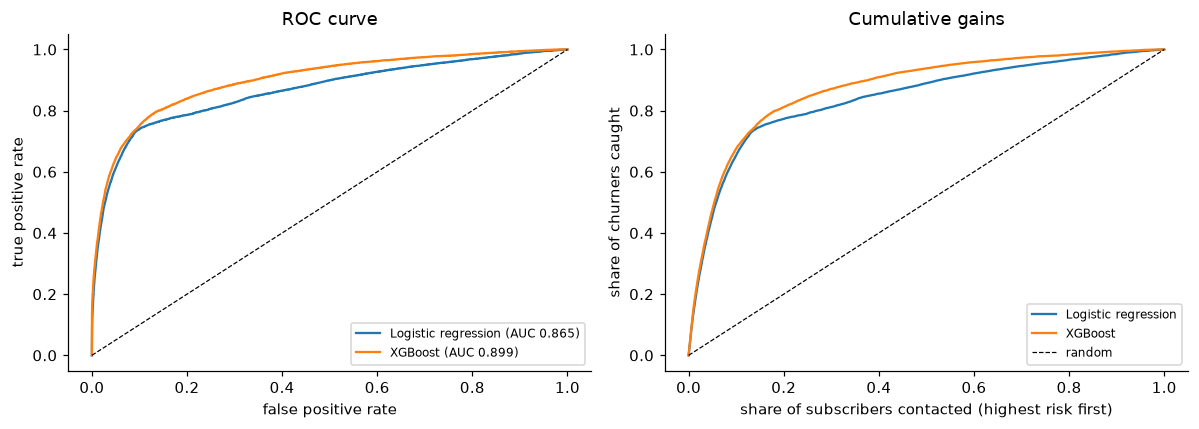

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, p in [("Logistic regression", p_lr), ("XGBoost", p_xgb)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    order = np.argsort(-p)
    captured = np.cumsum(y_test.values[order]) / y_test.sum()
    axes[1].plot(np.arange(1, len(p) + 1) / len(p), captured, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8, label="random")
axes[1].set(xlabel="share of subscribers contacted (highest risk first)",
            ylabel="share of churners caught", title="Cumulative gains")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()

## 5. What drives the predictions?

XGBoost **gain** importance (how much each feature improves the trees' splits) and the logistic regression's largest standardised coefficients (direction of effect: positive = more likely to churn).

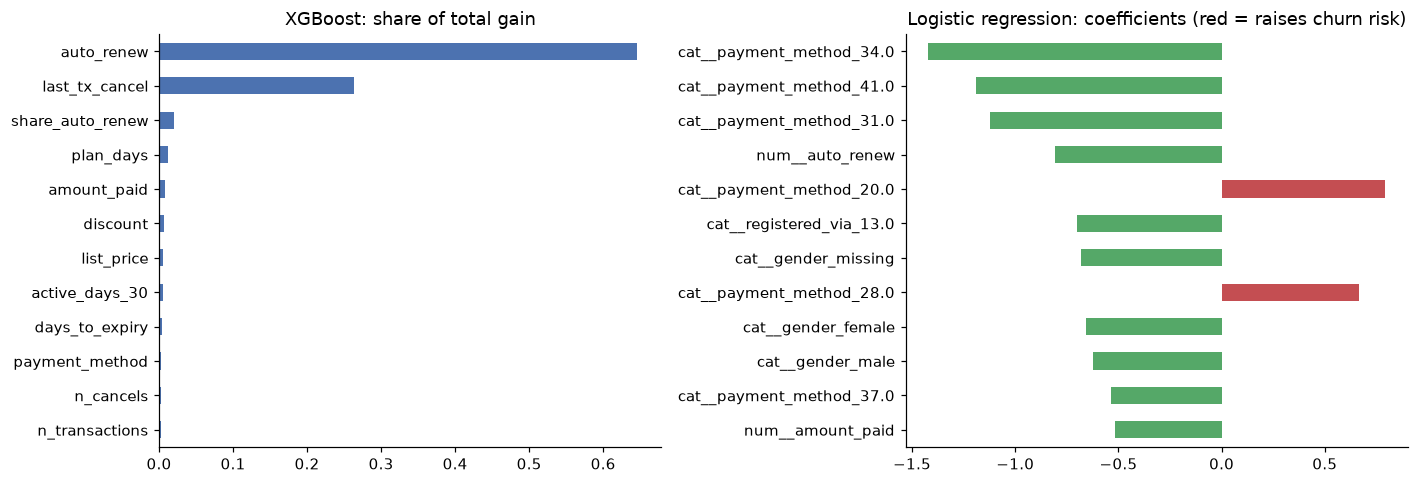

In [11]:
gain = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values()
lr_coef = pd.Series(logreg[-1].coef_[0], index=logreg[0].get_feature_names_out())
lr_top = lr_coef.reindex(lr_coef.abs().sort_values().index).tail(12)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(gain / gain.sum()).tail(12).plot.barh(ax=axes[0], color="#4C72B0", title="XGBoost: share of total gain")
lr_top.plot.barh(ax=axes[1], color=np.where(lr_top > 0, "#C44E52", "#55A868"),
                 title="Logistic regression: coefficients (red = raises churn risk)")
plt.tight_layout()

## 6. Who is at risk?

Test-set subscribers grouped by the XGBoost churn probability. "At risk" = predicted probability at least **2x the baseline churn rate**.

In [12]:
at_risk_cut = 2 * base_rate
tiers = pd.cut(p_xgb, [0, at_risk_cut, 0.5, 1.0001],
               labels=[f"low (< {at_risk_cut:.0%})", f"at risk ({at_risk_cut:.0%}-50%)", "high (>= 50%)"],
               include_lowest=True)
risk = (pd.DataFrame({"tier": tiers, "churn": y_test.values})
          .groupby("tier", observed=True).churn
          .agg(users="size", actual_churn_rate="mean", churners="sum"))
risk["share_of_users"] = risk.users / risk.users.sum()
risk["share_of_churners"] = risk.churners / risk.churners.sum()

at_risk = p_xgb >= at_risk_cut
print(f"At risk (>= {at_risk_cut:.1%}): {at_risk.mean():.1%} of subscribers, "
      f"containing {y_test[at_risk].sum() / y_test.sum():.1%} of all churners")
risk

At risk (>= 12.8%): 11.5% of subscribers, containing 70.6% of all churners


,users,actual_churn_rate,churners,share_of_users,share_of_churners
tier,,,,,
low (< 13%),175757,0.021,"3,730.000",0.885,0.294
at risk (13%-50%),16639,0.273,"4,550.000",0.084,0.358
high (>= 50%),6191,0.713,"4,414.000",0.031,0.348


## 7. Segments and retention actions

Listening activity looks like a weak driver overall (Cohen's d ≈ 0.1), but that hides an interaction: auto-renewers rarely churn however little they listen, while among **manual** renewers, low listening sharply raises churn.

In [13]:
manual_monthly = df[(df.auto_renew == 0) & (df.last_tx_cancel == 0) & (df.plan_days == 30)]
pd.concat({
    "manual monthly renewers": manual_monthly.groupby("activity_30d", observed=True).is_churn.mean(),
    "auto-renewers": df[df.auto_renew == 1].groupby("activity_30d", observed=True).is_churn.mean(),
}, axis=1).rename_axis("active listening days, last 30")

,manual monthly renewers,auto-renewers
"active listening days, last 30",,
0 days,0.767,0.049
1-5 days,0.526,0.036
6-15 days,0.352,0.028
16-30 days,0.194,0.019


Rule-based segments built from these drivers, assigned in priority order so each subscriber lands in exactly one. They describe the whole cohort (actual churn, not predictions), so they can be acted on directly.

In [14]:
manual = df.auto_renew == 0
seg_rules = [
    ("1. Cancelled last plan",            df.last_tx_cancel == 1),
    ("2. Short / trial plan (< 30 d)",    df.plan_days < 30),
    ("3. Manual, prepaid long plan",      manual & (df.plan_days > 30)),
    ("4. Manual monthly, disengaged",     manual & (df.active_days_30 <= 5)),
    ("5. Manual monthly, engaged",        manual),
]
df["segment"] = "6. Auto-renewers (no action)"
for name, rule in reversed(seg_rules):
    df.loc[rule.fillna(False), "segment"] = name

segments = df.groupby("segment").is_churn.agg(users="size", churn_rate="mean", churners="sum")
segments["share_of_users"] = segments.users / len(df)
segments["share_of_churners"] = segments.churners / df.is_churn.sum()
segments["churn_vs_baseline"] = segments.churn_rate / base_rate
segments

,users,churn_rate,churners,share_of_users,share_of_churners,churn_vs_baseline
segment,,,,,,
1. Cancelled last plan,9542,0.795,"7,589.000",0.010,0.120,12.442
2. Short / trial plan (< 30 d),3627,0.733,"2,659.000",0.004,0.042,11.469
"3. Manual, prepaid long plan",22756,0.476,"10,829.000",0.023,0.171,7.445
"4. Manual monthly, disengaged",7929,0.544,"4,311.000",0.008,0.068,8.506
"5. Manual monthly, engaged",77798,0.238,"18,533.000",0.078,0.292,3.727
6. Auto-renewers (no action),871279,0.022,"19,550.000",0.877,0.308,0.351


| Segment | Proposed action | How to test it |
|---|---|---|
| 1. Cancelled last plan | Win-back before expiry: ask why they cancelled, offer a discounted month | A/B: offer vs. holdout, measure 30-day renewal |
| 2. Short / trial plan | Convert trial to monthly with an end-of-trial offer | A/B on offer size, measure paid conversion |
| 3. Manual, prepaid long plan | Early renewal reminder plus a loyalty price for renewing (or switching to auto-renew) | A/B on reminder timing, measure renewal |
| 4. Manual monthly, disengaged | Re-engage first (personalised playlists, new releases), then remind to renew | A/B on campaign vs. holdout, measure listening and renewal |
| 5. Manual monthly, engaged | They use the product but must remember to pay: incentive to switch on auto-renew | A/B on incentive, measure auto-renew opt-in and renewal |

Auto-renewers churn at roughly 2-3% and need no proactive spend. The segment churn rates show where retention spend is likely to pay off; the effect of each action is unknown until tested, so each one comes with an experiment.

## 8. Out-of-time test: does the model hold up a month later?

The test set above is a random 20% of the **same** February cohort. In practice the model would be trained on past months and used on the next one. So here the models trained on February are scored, unchanged, on the **March 2017 cohort** (`train_v2.csv`), with features built from data up to 28 Feb.

Four evaluation sets:
- **Feb, random test**: the in-time result from section 4, for comparison.
- **Mar, all users**: features use both transaction files (everything known on 28 Feb).
- **Mar, users not in the Feb cohort**: about 9% of March users were never in the training cohort, so this is the strictest check.
- **Mar, original transactions file only**: the same data sources as training, to check that adding `transactions_v2.csv` doesn't change the picture.

In [15]:
def load(path):
    f = pd.read_parquet(path)
    cols = f.columns.drop(["msno", "gender"])
    f[cols] = f[cols].astype("float64")
    return f

def to_X(f):
    Xo = f[NUM + CAT].copy()
    for c in CAT:
        # Reuse the training categories; values never seen in training become missing.
        cats = X[c].cat.categories
        vals = Xo[c].astype("string").fillna("missing")
        Xo[c] = pd.Categorical(vals.where(vals.isin(cats)), categories=cats)
    return Xo

mar = load("../data/features_oot.parquet")
mar_v1 = load("../data/features_oot_v1tx.parquet")
new_users = ~mar.msno.isin(df.msno)
print(f"March cohort: {len(mar):,} users, churn {mar.is_churn.mean():.2%}; "
      f"{new_users.sum():,} ({new_users.mean():.1%}) were not in the February cohort")

eval_sets = [
    ("Feb, random 20% test (in-time)", X_test, y_test),
    ("Mar, all users (out-of-time)", to_X(mar), mar.is_churn),
    ("Mar, users not in Feb cohort", to_X(mar[new_users]), mar.is_churn[new_users]),
    ("Mar, original transactions file only", to_X(mar_v1), mar_v1.is_churn),
]
rows = []
for name, Xs, ys in eval_sets:
    p_l = logreg.predict_proba(Xs)[:, 1]
    p_x = model.predict_proba(Xs)[:, 1]
    top = p_x >= np.quantile(p_x, 0.9)
    rows.append({
        "evaluation set": name,
        "users": len(ys),
        "actual churn": ys.mean(),
        "mean predicted churn (XGB)": p_x.mean(),
        "LR ROC-AUC": roc_auc_score(ys, p_l),
        "XGB ROC-AUC": roc_auc_score(ys, p_x),
        "XGB PR-AUC": average_precision_score(ys, p_x),
        "churners in XGB top 10%": ys[top].sum() / ys.sum(),
    })
oot = pd.DataFrame(rows).set_index("evaluation set")
oot

March cohort: 970,960 users, churn 8.99%; 89,259 (9.2%) were not in the February cohort


,users,actual churn,mean predicted churn (XGB),LR ROC-AUC,XGB ROC-AUC,XGB PR-AUC,churners in XGB top 10%
evaluation set,,,,,,,
"Feb, random 20% test (in-time)",198587,0.064,0.064,0.865,0.899,0.578,0.676
"Mar, all users (out-of-time)",970960,0.090,0.065,0.817,0.873,0.601,0.604
"Mar, users not in Feb cohort",89259,0.398,0.291,0.851,0.863,0.767,0.210
"Mar, original transactions file only",970960,0.090,0.063,0.822,0.858,0.582,0.596


**Reading the table:**
- **New users churn far more** (about 40%; many are on short or first plans). With that many churners, a top 10% can hold at most about a quarter of them, so the "top 10%" column isn't comparable across rows for that subset. Use its ROC-AUC and PR-AUC instead.
- **Combining both transaction files helps** (ROC-AUC 0.873 vs 0.858). The original file is missing some pre-cutoff transactions for March users.
- **ROC-AUC measures ranking**, so it can hold up even when the overall churn level shifts (6.4% in February vs. 9.0% in March). The *mean predicted churn* column shows whether the probabilities themselves still match reality. If they don't, the ranking is still usable for choosing whom to target, but probability cut-offs such as the "at risk" threshold would need recalibrating on recent data before use.

## 9. Summary numbers

In [16]:
seg_top = segments.drop("6. Auto-renewers (no action)")
summary = {
    "labelled subscribers": f"{len(df):,}",
    "baseline churn rate": f"{base_rate:.2%}",
    "features used in models": len(NUM) + len(CAT),
    "logistic regression ROC-AUC": f"{roc_auc_score(y_test, p_lr):.3f}",
    "XGBoost ROC-AUC": f"{roc_auc_score(y_test, p_xgb):.3f}",
    "XGBoost PR-AUC": f"{average_precision_score(y_test, p_xgb):.3f}",
    "XGBoost ROC-AUC, March out-of-time": f"{oot.loc['Mar, all users (out-of-time)', 'XGB ROC-AUC']:.3f}",
    "XGBoost ROC-AUC, March users not in Feb cohort": f"{oot.loc['Mar, users not in Feb cohort', 'XGB ROC-AUC']:.3f}",
    "share of subscribers flagged at risk": f"{at_risk.mean():.1%}",
    "share of churners inside the at-risk group": f"{y_test[at_risk].sum() / y_test.sum():.1%}",
    "churners caught by contacting top 10%": f"{top_k_stats(p_xgb, 0.10)[1]:.1%}",
    "churn in auto-renew vs manual": f"{df.loc[df.auto_renew == 1, 'is_churn'].mean():.1%} vs {df.loc[df.auto_renew == 0, 'is_churn'].mean():.1%}",
    "segments 1-5: share of users / share of churners": f"{seg_top.share_of_users.sum():.1%} / {seg_top.share_of_churners.sum():.1%}",
}
pd.Series(summary).to_frame("value")

,value
labelled subscribers,"992,931"
baseline churn rate,6.39%
features used in models,27
logistic regression ROC-AUC,0.865
XGBoost ROC-AUC,0.899
XGBoost PR-AUC,0.578
"XGBoost ROC-AUC, March out-of-time",0.873
"XGBoost ROC-AUC, March users not in Feb cohort",0.863
share of subscribers flagged at risk,11.5%
share of churners inside the at-risk group,70.6%
